# **Segmentacion RFM de clientes de tarjeta debito con optimizacion de hiperparametros**

**Problema.** Se tiene informacion transaccional de ~640 mil clientes de tarjeta debito. Se busca agruparlos en segmentos homogeneos segun su comportamiento de compra, usando las variables **RFM**:

- **R**ecencia (`recency_dias`): dias desde la ultima transaccion.
- **F**recuencia (`frecuencia`): numero de transacciones en la ventana de 6 meses.
- **M**onto (`valor_total`): valor total transado (COP).

**Que se optimiza.** Los hiperparametros de tres algoritmos de clustering (K-Means, Gaussian Mixture y K-Prototypes) para maximizar la calidad de los segmentos (coeficiente de silhouette), con la restriccion de que todos los segmentos sean accionables (al menos 5% de los clientes). Se comparan tres estrategias de busqueda con el mismo presupuesto: Grid Search, Random Search y optimizacion bayesiana (TPE).

**Flujo:** carga de datos → analisis exploratorio → escalamiento → linea base → optimizacion → comparacion de modelos → modelo final → perfilamiento de segmentos.


## **Importacion de librerias**


In [1]:
import itertools
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from kmodes.kprototypes import KPrototypes
from optuna.samplers import GridSampler, RandomSampler, TPESampler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import PowerTransformer

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

SEED = 42

/home/user/proyecto-optimizacion-ia/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---

## **Carga de datos**


In [2]:
df = pd.read_parquet("./data/tabla_total.parquet").dropna()

In [3]:
df_debito = df[df["producto"].str.contains("DEBITO", case=False, na=False)].copy()

---

## **Analisis exploratorio: Variables RFM**


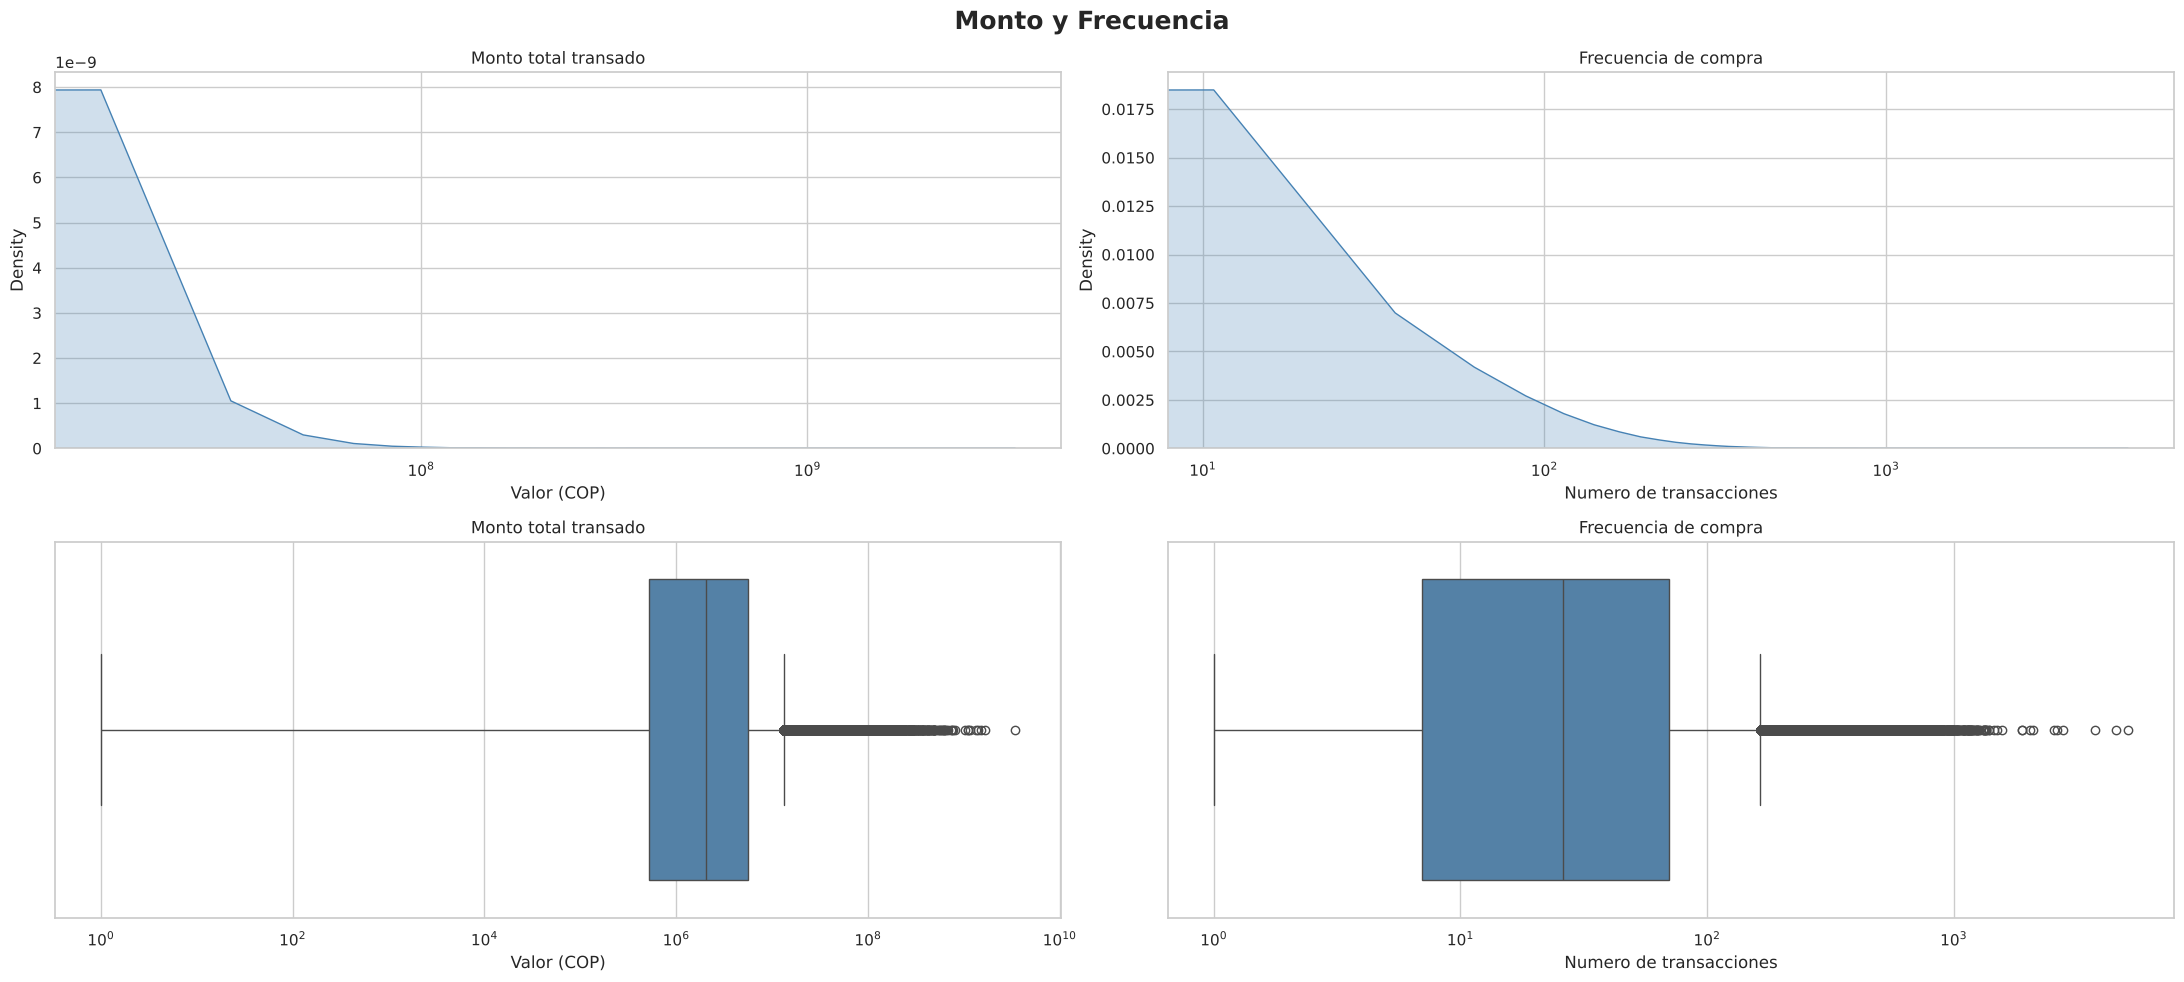

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(22, 10))

fig.suptitle(
    "Monto y Frecuencia",
    fontsize=18,
    fontweight="bold",
)

## MONTO TOTAL
# Gráfico de densidad
sns.kdeplot(
    data=df_debito,
    x="valor_total",
    fill=True,
    color="steelblue",
    ax=axes[0, 0],
)

axes[0, 0].set_title(f"Monto total transado")
axes[0, 0].set_xlabel("Valor (COP)")
axes[0, 0].set_xscale("log")

# Boxplot
sns.boxplot(data=df_debito, x="valor_total", color="steelblue", ax=axes[1, 0])

axes[1, 0].set_title(f"Monto total transado")
axes[1, 0].set_xlabel("Valor (COP)")
axes[1, 0].set_xscale("log")

## FRECUENCIA
# Gráfico de densidad
sns.kdeplot(
    data=df_debito,
    x="frecuencia",
    fill=True,
    color="steelblue",
    ax=axes[0, 1],
)

axes[0, 1].set_title(f"Frecuencia de compra")
axes[0, 1].set_xlabel("Numero de transacciones")
axes[0, 1].set_xscale("log")

# Boxplot
sns.boxplot(data=df_debito, x="frecuencia", color="steelblue", ax=axes[1, 1])

axes[1, 1].set_title(f"Frecuencia de compra")
axes[1, 1].set_xlabel("Numero de transacciones")
axes[1, 1].set_xscale("log")

plt.tight_layout()
plt.show()

Las graficas anteriores demuestran que hay un sesgo muy grande en los datos del valor transado de todos los clientes. Esto se debe a que el dataset contiene clientes de Bancolombia de todos los segmentos, y de acuerdo a esto habran diferentes capacidades economicas en el consumo con tarjeta debito. Adicionalmente, los datos no discriminan persona natural o juridica, lo cual hace que la diferencia aumente mas, pues un cliente catalogado como persona juridica posiblemente corresponda con alguna empresa, las cuales suelen hacer gastos aun mayores. Del mismo modo, para la frecuencia se observa un comportamiento similar.


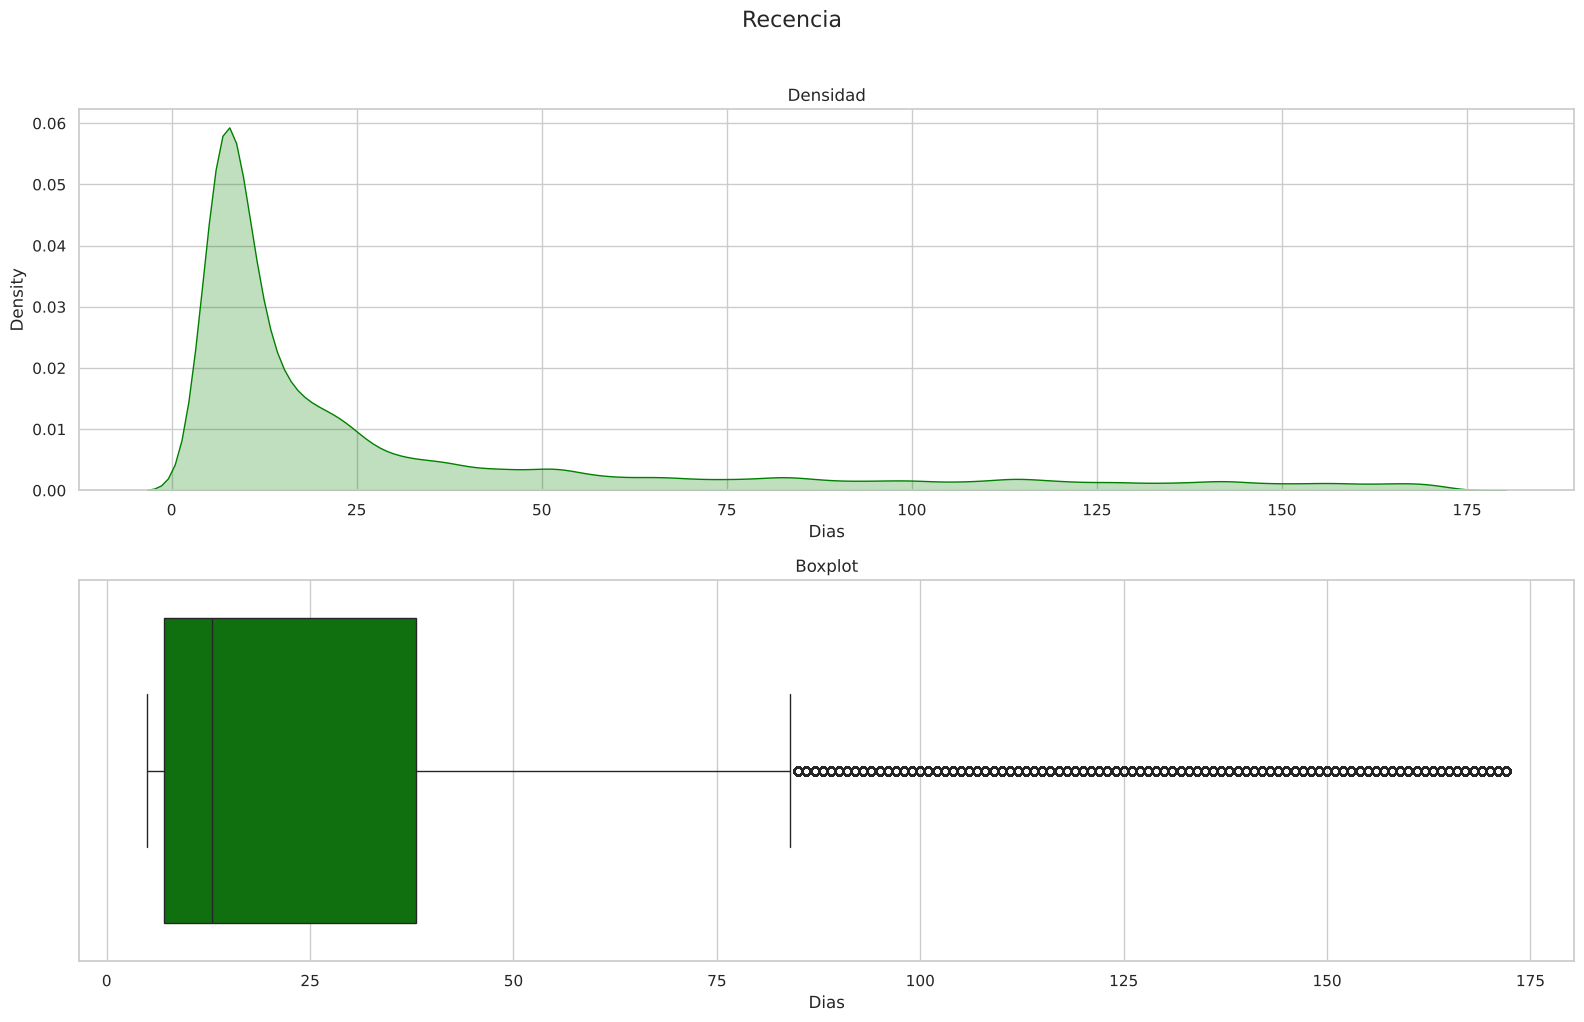

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle("Recencia", fontsize=16, y=1.02)

# 1. Density Plots
sns.kdeplot(
    data=df_debito,
    x="recency_dias",
    fill=True,
    color="green",
    ax=axes[0],
)
axes[0].set_title("Densidad")
axes[0].set_xlabel("Dias")

axes[1].set_title("Boxplot")
axes[1].set_xlabel("Dias")

# # 2. Boxplots
sns.boxplot(data=df_debito, x="recency_dias", color="green", ax=axes[1])
axes[1].set_title("Boxplot")


plt.tight_layout()
plt.show()

Para la variable de recencia se observa un comportamiento sesgado, aunque no de la misma magnitud que para la frecuencia de compra y monto total transado. Esto tiene sentido ya que la recencia es un valor que esta registrada en la ventana temporal del analisis, la cual corresponde a 6 meses. Esto significa que por mas sesgado que este un valor de recencia, este no superara aproximadamente los 180 dias.

Estas graficas son la razon de la cual es necesario aplicar un escalamiento en los datos. Se observa que las tres variables poseen distribuciones sesgadas, y adicionalmente se miden en unidades diferentes, por lo cual el escalamiento se hace necesario antes de proceder a aplicar el algoritmo de clustering.


---

## **Escalamiento de datos**


In [6]:
num_cols = ["recency_dias", "frecuencia", "valor_total"]
cat_cols = ["desc_segmento", "desc_genero"]

pt = PowerTransformer(method="yeo-johnson", standardize=True)

In [7]:
df_debito_num_scaled = pd.DataFrame(
    pt.fit_transform(df_debito[num_cols]), columns=num_cols, index=df_debito.index
)

df_debito_procesado = pd.concat([df_debito_num_scaled, df_debito[cat_cols]], axis=1)

display(df_debito_procesado.head())

,recency_dias,frecuencia,valor_total,desc_segmento,desc_genero
5080290,0.489137,-0.374214,-0.738656,PERSONAL,FEMENINO
2077692,-0.809934,0.588348,0.344044,PERSONAL,FEMENINO
5017407,1.368864,-0.374214,-0.551993,PLUS,MASCULINO
4877830,-1.268048,1.015343,0.910170,INDEPENDIENTES,MASCULINO
4752156,-0.139982,0.074557,0.057239,PERSONAL,FEMENINO


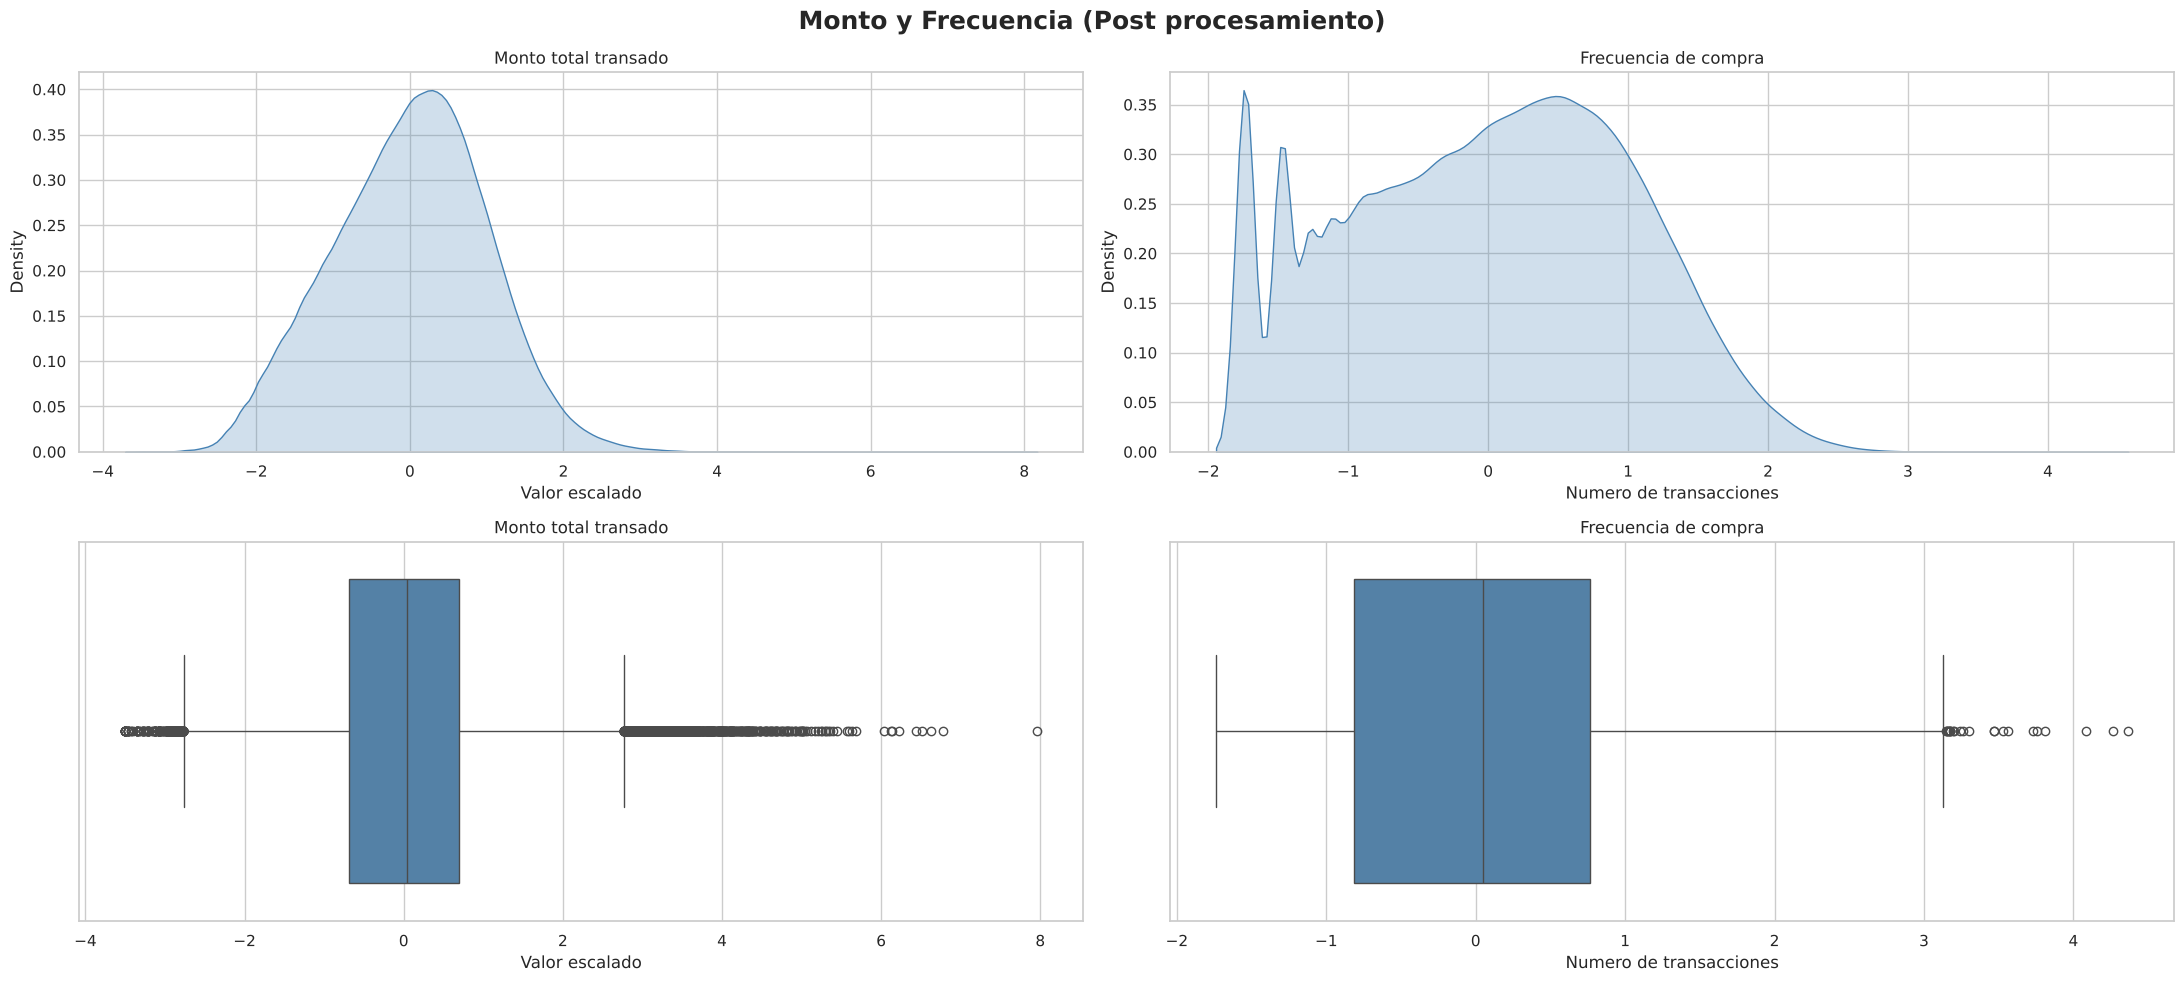

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(22, 10))

fig.suptitle(
    "Monto y Frecuencia (Post procesamiento)",
    fontsize=18,
    fontweight="bold",
)

## MONTO TOTAL
# Gráfico de densidad
sns.kdeplot(
    data=df_debito_procesado,
    x="valor_total",
    fill=True,
    color="steelblue",
    ax=axes[0, 0],
)

axes[0, 0].set_title(f"Monto total transado")
axes[0, 0].set_xlabel("Valor escalado")

# Boxplot
sns.boxplot(data=df_debito_procesado, x="valor_total", color="steelblue", ax=axes[1, 0])

axes[1, 0].set_title(f"Monto total transado")
axes[1, 0].set_xlabel("Valor escalado")

## FRECUENCIA
# Gráfico de densidad
sns.kdeplot(
    data=df_debito_procesado,
    x="frecuencia",
    fill=True,
    color="steelblue",
    ax=axes[0, 1],
)

axes[0, 1].set_title(f"Frecuencia de compra")
axes[0, 1].set_xlabel("Numero de transacciones")

# Boxplot
sns.boxplot(data=df_debito_procesado, x="frecuencia", color="steelblue", ax=axes[1, 1])

axes[1, 1].set_title(f"Frecuencia de compra")
axes[1, 1].set_xlabel("Numero de transacciones")

plt.tight_layout()
plt.show()

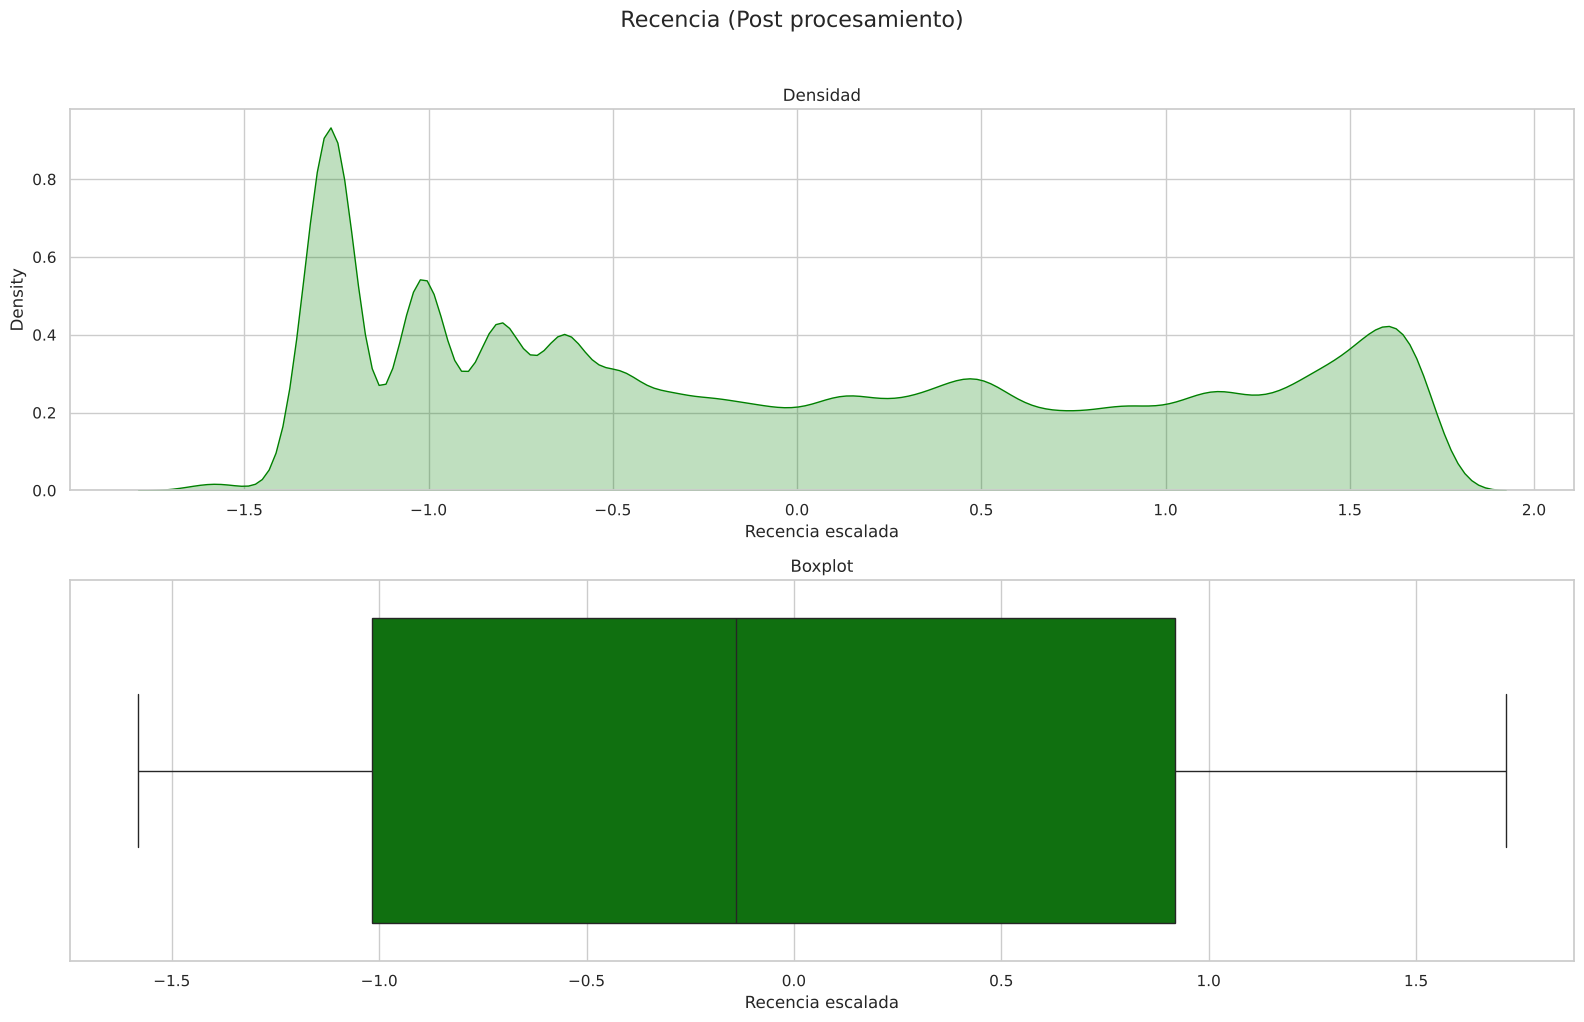

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle("Recencia (Post procesamiento)", fontsize=16, y=1.02)

# 1. Density Plots
sns.kdeplot(
    data=df_debito_procesado,
    x="recency_dias",
    fill=True,
    color="green",
    ax=axes[0],
)
axes[0].set_title("Densidad")
axes[0].set_xlabel("Recencia escalada")

axes[1].set_title("Boxplot")
axes[1].set_xlabel("Recencia escalada")

# # 2. Boxplots
sns.boxplot(data=df_debito_procesado, x="recency_dias", color="green", ax=axes[1])
axes[1].set_title("Boxplot")


plt.tight_layout()
plt.show()

---

## **Linea base: K-Means**


In [10]:
# Variables RFM seleccionadas
X_rfm = df_debito_procesado[["recency_dias", "frecuencia", "valor_total"]]

### Linea base: barrido manual del numero de clusters

Como punto de partida se estudia unicamente el numero de clusters de K-Means, dejando el resto de hiperparametros en sus valores por defecto. El algoritmo de K-Means nos exige especificar manualmente este numero, por lo cual, antes de ingresarlo al modelo final, podriamos estudiar como se comportan ciertas metricas para diferentes numeros de clusters. Sin embargo, debemos de tener en cuenta que estas metricas son altamente heuristicas, por lo cual no se recomienda siempre tenerlas como fuente de la verdad, sino como una referencia adicional para la seleccion de este numero adecuado, ya que en la vida real debemos de tener en cuenta que esto puede estar directamente ligado a decisiones estrategicas o de negocio para posteriormente volver accionables estos segmentos resultantes.


In [11]:
inertia = []
silhouette_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_rfm)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_rfm, kmeans.labels_, sample_size=25_000, random_state=42)
    )

    print(f"k={k}, inertia={kmeans.inertia_}, silhouette_score={silhouette_scores[-1]}")

k=2, inertia=802282.2554515027, silhouette_score=0.4763959026948591


k=3, inertia=574192.1923398394, silhouette_score=0.37077943425651516


k=4, inertia=458831.7241444953, silhouette_score=0.3534393368719187


k=5, inertia=384447.3152225533, silhouette_score=0.3327511226744853


k=6, inertia=331874.10462554416, silhouette_score=0.3116011012579045


k=7, inertia=299875.96940857277, silhouette_score=0.3009990665206052


La optimizacion de hiperparametros realmente no es un proceso infalible, y en la vida real normalmente los datos no estan completamente separados entre si. En este caso observamos puntajes de silhouette relativamente bajos, pero normales para el contexto de clustering con variables RFM. Tambien esto puede ser debido a que los clusters resultantes realmente no tienen tamanos esfericos, por lo cual otras tecnicas mas avanzadas de clustering podrian generar mejores resultados para tamanos mas irregulares.


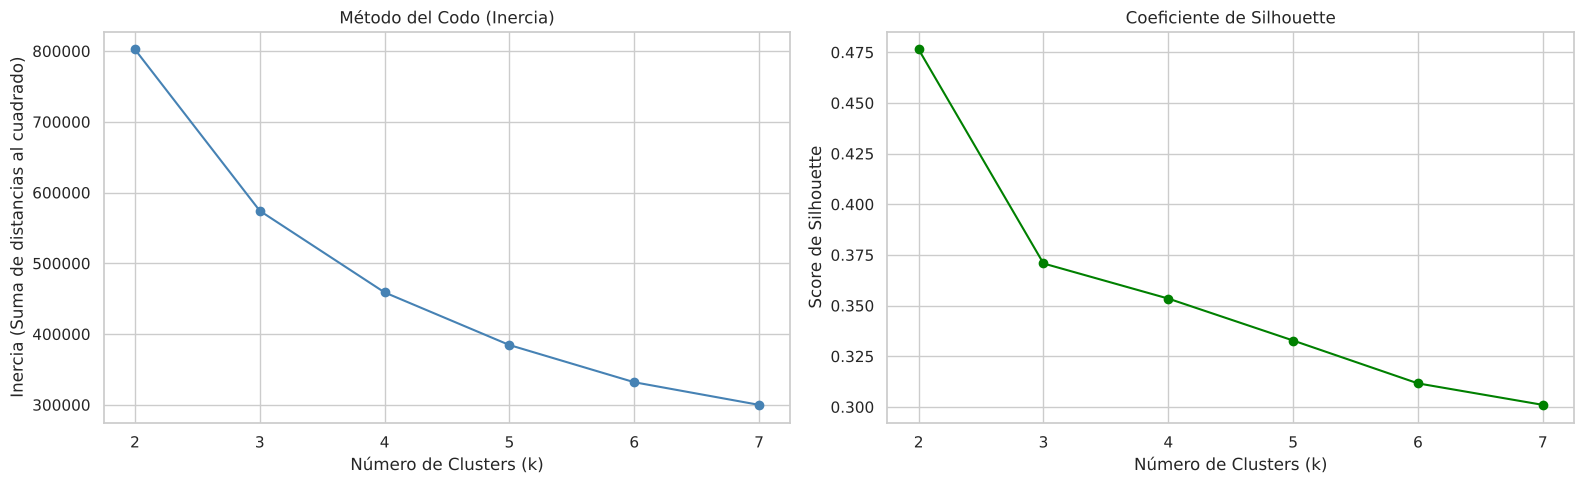

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Metodo del codo
axes[0].plot(K_range, inertia, marker="o", color="steelblue")
axes[0].set_title("Método del Codo (Inercia)")
axes[0].set_xlabel("Número de Clusters (k)")
axes[0].set_ylabel("Inercia (Suma de distancias al cuadrado)")

# Gráfico de Silhouette
axes[1].plot(K_range, silhouette_scores, marker="o", color="green")
axes[1].set_title("Coeficiente de Silhouette")
axes[1].set_xlabel("Número de Clusters (k)")
axes[1].set_ylabel("Score de Silhouette")

plt.tight_layout()
plt.show()

---

## **Optimizacion de hiperparametros**

El barrido anterior solo explora un hiperparametro de un unico algoritmo. En esta seccion el problema se plantea formalmente como un problema de optimizacion:

$$\theta^* = \arg\max_{\theta \in \Theta} \; S(\theta) \quad \text{sujeto a} \quad \min_j \frac{n_j(\theta)}{n} \geq 5\%$$

- **Variables de decision ($\theta$):** los hiperparametros de cada algoritmo de clustering (numero de clusters, inicializacion, tipo de covarianza, peso de las variables categoricas, etc.).
- **Funcion objetivo ($S$):** coeficiente de silhouette calculado siempre sobre las mismas tres variables RFM escaladas, de modo que los tres algoritmos sean comparables entre si.
- **Restriccion:** ningun cluster puede tener menos del 5% de los clientes, pues un segmento tan pequeno no es accionable comercialmente. Las configuraciones que la incumplen se penalizan con $S=-1$.
- **Espacio de busqueda ($\Theta$):** se restringe a $k \geq 3$. La linea base muestra que $k=2$ maximiza el silhouette, pero esa particion solo separa clientes activos de inactivos y no aporta una segmentacion util.

La funcion objetivo no es derivable ni tiene forma cerrada (cada evaluacion implica entrenar un modelo), asi que se trata como una caja negra y se comparan tres estrategias de busqueda con el mismo presupuesto de evaluaciones: **Grid Search**, **Random Search** y **optimizacion bayesiana (TPE, Optuna)**.

Se comparan tres algoritmos:

| Algoritmo | Hiperparametros optimizados |
|---|---|
| K-Means | `n_clusters`, `init`, `n_init` |
| Gaussian Mixture (GMM) | `n_components`, `covariance_type`, `reg_covar`, `init_params` |
| K-Prototypes | `n_clusters`, `gamma`, `init` (incluye segmento y genero como variables categoricas) |


### Muestras de busqueda y evaluacion

Cada evaluacion de la funcion objetivo entrena un modelo, por lo que la busqueda se hace sobre una muestra aleatoria de clientes. Una segunda muestra, disjunta de la primera, se reserva para comparar los modelos finalistas con datos que no participaron en la busqueda.


In [13]:
N_BUSQUEDA = 30_000  # clientes usados para entrenar durante la busqueda
N_SILHOUETTE = 10_000  # subconjunto sobre el que se calcula el silhouette
N_KPROTO = 6_000  # K-Prototypes es mucho mas lento: se entrena con menos clientes
N_EVAL = 20_000  # muestra reservada para la comparacion final
MIN_FRAC = 0.05  # tamano minimo de cluster (restricción)

X_all = X_rfm.to_numpy()
C_all = df_debito_procesado[cat_cols].to_numpy()

perm = np.random.RandomState(SEED).permutation(len(X_all))
idx_busqueda = perm[:N_BUSQUEDA]
idx_eval = perm[N_BUSQUEDA : N_BUSQUEDA + N_EVAL]

print(f"Total clientes: {len(X_all):,}")
print(f"Muestra de busqueda: {len(idx_busqueda):,} | Muestra de evaluacion: {len(idx_eval):,}")

Total clientes: 637,940
Muestra de busqueda: 30,000 | Muestra de evaluacion: 20,000


### Modelos y espacio de busqueda


In [14]:
CAT_IDX = [3, 4]  # posicion de las columnas categoricas en la matriz mixta


def crear_modelo(nombre, p):
    if nombre == "K-Means":
        return KMeans(
            n_clusters=p["n_clusters"],
            init=p["init"],
            n_init=p["n_init"],
            random_state=SEED,
        )
    if nombre == "GMM":
        return GaussianMixture(
            n_components=p["n_clusters"],
            covariance_type=p["covariance_type"],
            reg_covar=p["reg_covar"],
            init_params=p["init_params"],
            random_state=SEED,
        )
    return KPrototypes(
        n_clusters=p["n_clusters"],
        gamma=p["gamma"],
        init=p["init"],
        n_init=1,
        max_iter=20,
        random_state=SEED,
    )


def datos_modelo(nombre, idx):
    """Matriz de entrada de cada modelo. K-Prototypes recibe RFM + categoricas."""
    if nombre == "K-Prototypes":
        X = np.column_stack([X_all[idx].astype(object), C_all[idx]])
        return X, {"categorical": CAT_IDX}
    return X_all[idx], {}


def sugerir(trial, nombre):
    """Espacio de busqueda de cada modelo."""
    if nombre == "K-Means":
        return {
            "n_clusters": trial.suggest_int("n_clusters", 3, 8),
            "init": trial.suggest_categorical("init", ["k-means++", "random"]),
            "n_init": trial.suggest_categorical("n_init", [1, 5, 10]),
        }
    if nombre == "GMM":
        return {
            "n_clusters": trial.suggest_int("n_clusters", 3, 8),
            "covariance_type": trial.suggest_categorical(
                "covariance_type", ["full", "tied", "diag", "spherical"]
            ),
            "reg_covar": trial.suggest_float("reg_covar", 1e-6, 1e-1, log=True),
            "init_params": trial.suggest_categorical(
                "init_params", ["kmeans", "random_from_data"]
            ),
        }
    return {
        "n_clusters": trial.suggest_int("n_clusters", 3, 6),
        "gamma": trial.suggest_float("gamma", 0.01, 2.0, log=True),
        "init": trial.suggest_categorical("init", ["Huang", "Cao"]),
    }


# Grid Search solo puede evaluar una malla discreta de valores
GRILLAS = {
    "K-Means": {
        "n_clusters": [3, 4, 5, 6, 7, 8],
        "init": ["k-means++", "random"],
        "n_init": [1, 5, 10],
    },
    "GMM": {
        "n_clusters": [3, 4, 5, 6, 7, 8],
        "covariance_type": ["full", "tied", "diag", "spherical"],
        "reg_covar": [1e-6, 1e-3],
        "init_params": ["kmeans"],
    },
    "K-Prototypes": {
        "n_clusters": [3, 4, 5, 6],
        "gamma": [0.05, 0.25, 1.0],
        "init": ["Huang", "Cao"],
    },
}

# Presupuesto: todas las estrategias reciben tantas evaluaciones como puntos tiene la malla
PRESUPUESTO = {m: int(np.prod([len(v) for v in g.values()])) for m, g in GRILLAS.items()}
PRESUPUESTO

{'K-Means': 36, 'GMM': 48, 'K-Prototypes': 24}

### Funcion objetivo


In [15]:
_cache = {}


def evaluar(nombre, params):
    """Entrena una configuracion y devuelve silhouette (con penalizacion) y tamano minimo de cluster."""
    clave = (nombre, tuple(sorted(params.items())))
    # Todo es determinista: una configuracion ya vista no se reentrena. Por eso el costo de cada
    # estrategia se mide en numero de evaluaciones y no en segundos.
    if clave in _cache:
        return _cache[clave]

    idx = idx_busqueda[:N_KPROTO] if nombre == "K-Prototypes" else idx_busqueda
    X, kwargs = datos_modelo(nombre, idx)
    labels = crear_modelo(nombre, params).fit_predict(X, **kwargs)

    frac_min = np.bincount(labels, minlength=params["n_clusters"]).min() / len(labels)
    if frac_min < MIN_FRAC:
        valor = -1.0
    else:
        n = min(N_SILHOUETTE, len(idx))
        valor = silhouette_score(X_all[idx[:n]], labels[:n])

    _cache[clave] = (valor, frac_min)
    return _cache[clave]


def buscar(nombre, metodo):
    sampler = {
        "Grid": lambda: GridSampler(GRILLAS[nombre], seed=SEED),
        "Random": lambda: RandomSampler(seed=SEED),
        "TPE": lambda: TPESampler(seed=SEED),
    }[metodo]()

    def objetivo(trial):
        valor, frac_min = evaluar(nombre, sugerir(trial, nombre))
        trial.set_user_attr("frac_min", frac_min)
        return valor

    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objetivo, n_trials=PRESUPUESTO[nombre])
    return study

### Ejecucion de la busqueda


In [16]:
MODELOS = ["K-Means", "GMM", "K-Prototypes"]
METODOS = ["Grid", "Random", "TPE"]

estudios = {}
for nombre in MODELOS:
    for metodo in METODOS:
        estudios[nombre, metodo] = buscar(nombre, metodo)
        s = estudios[nombre, metodo]
        print(
            f"{nombre:<13} {metodo:<7} trials={len(s.trials):>3} "
            f"mejor silhouette={s.best_value:.4f}"
        )

K-Means       Grid    trials= 36 mejor silhouette=0.3671
K-Means       Random  trials= 36 mejor silhouette=0.3671
K-Means       TPE     trials= 36 mejor silhouette=0.3671


GMM           Grid    trials= 48 mejor silhouette=0.3590


GMM           Random  trials= 48 mejor silhouette=0.3588


GMM           TPE     trials= 48 mejor silhouette=0.3684


K-Prototypes  Grid    trials= 24 mejor silhouette=0.3650


K-Prototypes  Random  trials= 24 mejor silhouette=0.3650


K-Prototypes  TPE     trials= 24 mejor silhouette=0.3650


In [17]:
filas = []
for (nombre, metodo), s in estudios.items():
    for t in s.trials:
        filas.append(
            {
                "modelo": nombre,
                "metodo": metodo,
                "trial": t.number + 1,
                "silhouette": t.value,
                "frac_min": t.user_attrs["frac_min"],
                **t.params,
            }
        )

df_trials = pd.DataFrame(filas)
df_trials["factible"] = df_trials["silhouette"] > -1
df_trials["mejor_hasta_ahora"] = df_trials.groupby(["modelo", "metodo"])["silhouette"].cummax()

resumen = []
for (nombre, metodo), s in estudios.items():
    g = df_trials[(df_trials["modelo"] == nombre) & (df_trials["metodo"] == metodo)]
    resumen.append(
        {
            "modelo": nombre,
            "metodo": metodo,
            "evaluaciones": len(g),
            "configs. factibles": int(g["factible"].sum()),
            "mejor silhouette": s.best_value,
            "encontrado en trial": s.best_trial.number + 1,
            "mejores hiperparametros": s.best_params,
        }
    )

df_resumen = pd.DataFrame(resumen)
with pd.option_context("display.max_colwidth", None):
    display(df_resumen.style.format({"mejor silhouette": "{:.4f}"}).hide(axis="index"))

modelo,metodo,evaluaciones,configs. factibles,mejor silhouette,encontrado en trial,mejores hiperparametros
K-Means,Grid,36,36,0.3671,17,"{'n_clusters': 3, 'init': 'random', 'n_init': 5}"
K-Means,Random,36,36,0.3671,2,"{'n_clusters': 3, 'init': 'k-means++', 'n_init': 10}"
K-Means,TPE,36,36,0.3671,2,"{'n_clusters': 3, 'init': 'k-means++', 'n_init': 10}"
GMM,Grid,48,40,0.3590,6,"{'n_clusters': 3, 'covariance_type': 'spherical', 'reg_covar': 0.001, 'init_params': 'kmeans'}"
GMM,Random,48,39,0.3588,8,"{'n_clusters': 3, 'covariance_type': 'spherical', 'reg_covar': 2.2737628102536852e-05, 'init_params': 'kmeans'}"
GMM,TPE,48,44,0.3684,48,"{'n_clusters': 3, 'covariance_type': 'spherical', 'reg_covar': 0.09923214949228372, 'init_params': 'kmeans'}"
K-Prototypes,Grid,24,21,0.3650,3,"{'n_clusters': 3, 'gamma': 0.05, 'init': 'Huang'}"
K-Prototypes,Random,24,21,0.3650,2,"{'n_clusters': 3, 'gamma': 0.022853255256339213, 'init': 'Cao'}"
K-Prototypes,TPE,24,23,0.3650,2,"{'n_clusters': 3, 'gamma': 0.022853255256339213, 'init': 'Cao'}"


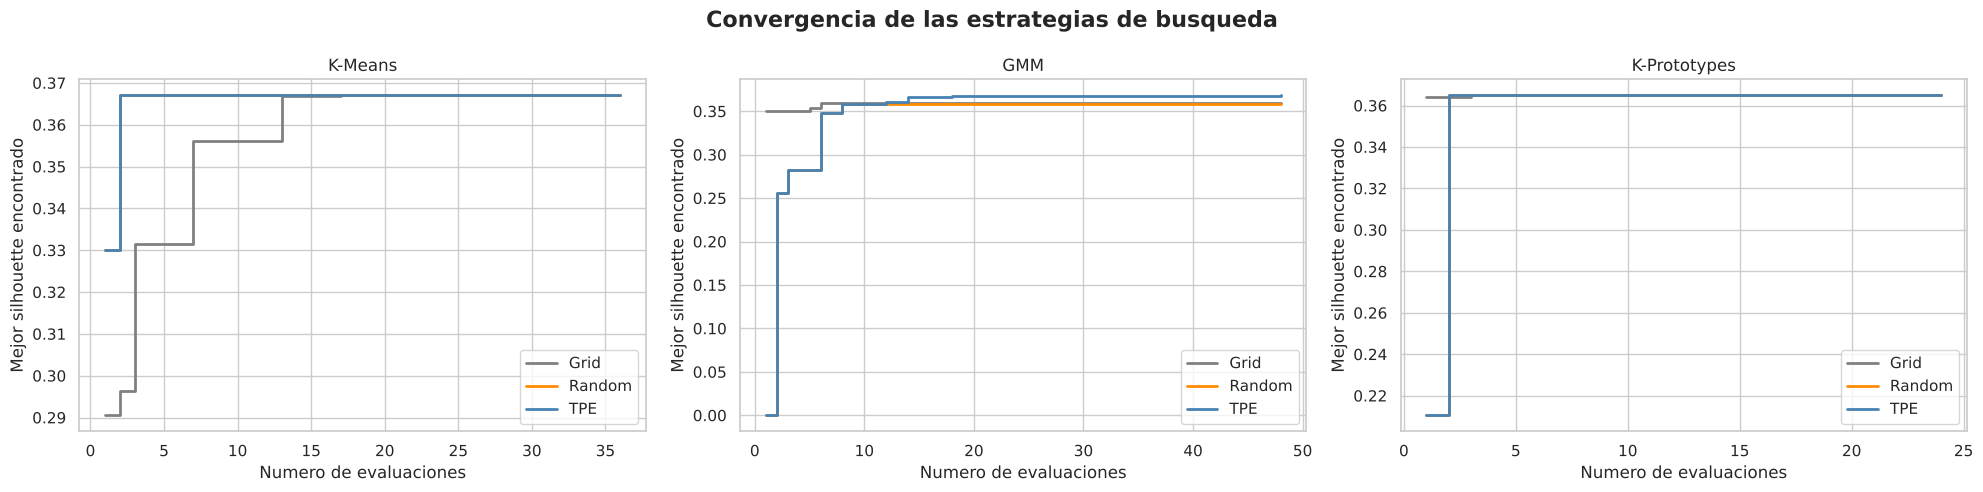

In [18]:
colores = {"Grid": "gray", "Random": "darkorange", "TPE": "steelblue"}

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle(
    "Convergencia de las estrategias de busqueda", fontsize=16, fontweight="bold"
)

for ax, nombre in zip(axes, MODELOS):
    for metodo in METODOS:
        g = df_trials[(df_trials["modelo"] == nombre) & (df_trials["metodo"] == metodo)]
        ax.step(
            g["trial"],
            g["mejor_hasta_ahora"].clip(lower=0),
            where="post",
            label=metodo,
            color=colores[metodo],
            linewidth=2,
        )
    ax.set_title(nombre)
    ax.set_xlabel("Numero de evaluaciones")
    ax.set_ylabel("Mejor silhouette encontrado")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

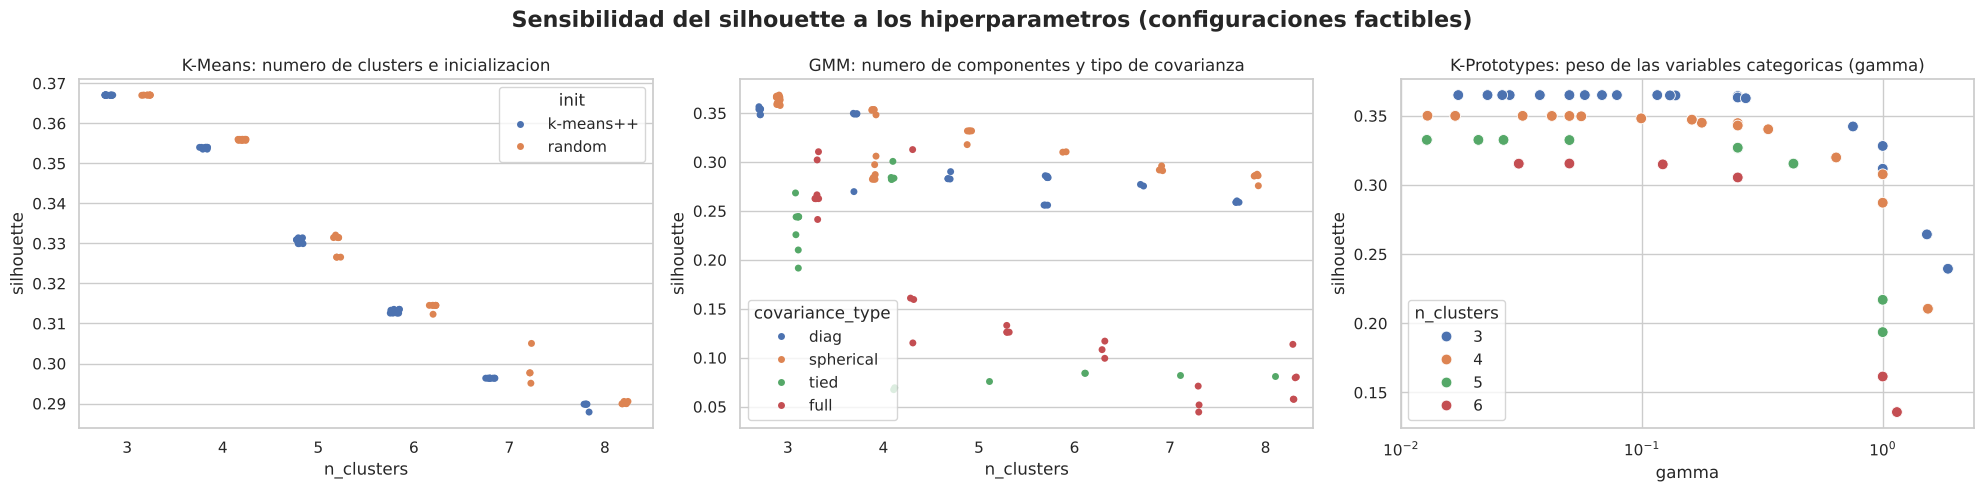

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle(
    "Sensibilidad del silhouette a los hiperparametros (configuraciones factibles)",
    fontsize=16,
    fontweight="bold",
)

fact = df_trials[df_trials["factible"]]

sns.stripplot(
    data=fact[fact["modelo"] == "K-Means"], x="n_clusters", y="silhouette",
    hue="init", dodge=True, ax=axes[0],
)
axes[0].set_title("K-Means: numero de clusters e inicializacion")

sns.stripplot(
    data=fact[fact["modelo"] == "GMM"], x="n_clusters", y="silhouette",
    hue="covariance_type", dodge=True, ax=axes[1],
)
axes[1].set_title("GMM: numero de componentes y tipo de covarianza")

kp = fact[fact["modelo"] == "K-Prototypes"]
sns.scatterplot(
    data=kp, x="gamma", y="silhouette", hue=kp["n_clusters"].astype(int).astype(str),
    hue_order=sorted(kp["n_clusters"].astype(int).astype(str).unique()), s=60, ax=axes[2],
)
axes[2].set_xscale("log")
axes[2].set_title("K-Prototypes: peso de las variables categoricas (gamma)")
axes[2].legend(title="n_clusters")

plt.tight_layout()
plt.show()

---

## **Comparacion de modelos**

La mejor configuracion de cada algoritmo se reentrena y se evalua sobre la muestra reservada (clientes que no participaron en la busqueda). Ademas del silhouette se reportan:

- **Davies-Bouldin** (menor es mejor) y **Calinski-Harabasz** (mayor es mejor), como metricas internas complementarias.
- **Estabilidad:** el modelo se reentrena sobre 5 submuestras distintas y se mide el acuerdo (Adjusted Rand Index) entre las particiones resultantes sobre la muestra de evaluacion. Un valor cercano a 1 indica que los segmentos no dependen de la muestra con la que se entreno.


In [20]:
mejores = {}
for nombre in MODELOS:
    mejor = max((estudios[nombre, m] for m in METODOS), key=lambda s: s.best_value)
    mejores[nombre] = mejor.best_params


def ajustar_y_predecir(nombre, params, idx_train, idx_pred):
    X_train, kwargs = datos_modelo(nombre, idx_train)
    X_pred, _ = datos_modelo(nombre, idx_pred)
    t0 = time.perf_counter()
    modelo = crear_modelo(nombre, params).fit(X_train, **kwargs)
    t_fit = time.perf_counter() - t0
    return modelo, modelo.predict(X_pred, **kwargs), t_fit


X_eval = X_all[idx_eval]
resto = perm[N_BUSQUEDA + N_EVAL :]
comparacion = []
for nombre in MODELOS:
    p = mejores[nombre]
    n_train = N_KPROTO if nombre == "K-Prototypes" else N_BUSQUEDA
    _, labels, t_fit = ajustar_y_predecir(nombre, p, idx_busqueda[:n_train], idx_eval)

    # estabilidad: 5 reentrenamientos sobre submuestras disjuntas
    particiones = [
        ajustar_y_predecir(nombre, p, resto[i * n_train : (i + 1) * n_train], idx_eval)[1]
        for i in range(5)
    ]
    ari = [adjusted_rand_score(a, b) for a, b in itertools.combinations(particiones, 2)]

    comparacion.append(
        {
            "modelo": nombre,
            "n_clusters": p["n_clusters"],
            "silhouette": silhouette_score(X_eval, labels),
            "davies_bouldin": davies_bouldin_score(X_eval, labels),
            "calinski_harabasz": calinski_harabasz_score(X_eval, labels),
            "cluster mas pequeno": np.bincount(labels).min() / len(labels),
            "estabilidad (ARI)": np.mean(ari),
            "tiempo de ajuste (s)": t_fit,
            "hiperparametros": p,
        }
    )

df_comparacion = pd.DataFrame(comparacion)
with pd.option_context("display.max_colwidth", None):
    display(
        df_comparacion.style.format(
            {
                "silhouette": "{:.4f}",
                "davies_bouldin": "{:.3f}",
                "calinski_harabasz": "{:,.0f}",
                "cluster mas pequeno": "{:.1%}",
                "estabilidad (ARI)": "{:.3f}",
                "tiempo de ajuste (s)": "{:.2f}",
            }
        ).hide(axis="index")
    )

modelo,n_clusters,silhouette,davies_bouldin,calinski_harabasz,cluster mas pequeno,estabilidad (ARI),tiempo de ajuste (s),hiperparametros
K-Means,3,0.3644,0.983,"22,918",28.7%,0.965,0.07,"{'n_clusters': 3, 'init': 'random', 'n_init': 5}"
GMM,3,0.3660,0.972,"22,686",26.3%,0.962,0.16,"{'n_clusters': 3, 'covariance_type': 'spherical', 'reg_covar': 0.09923214949228372, 'init_params': 'kmeans'}"
K-Prototypes,3,0.3648,0.983,"22,919",28.4%,0.958,4.52,"{'n_clusters': 3, 'gamma': 0.05, 'init': 'Huang'}"


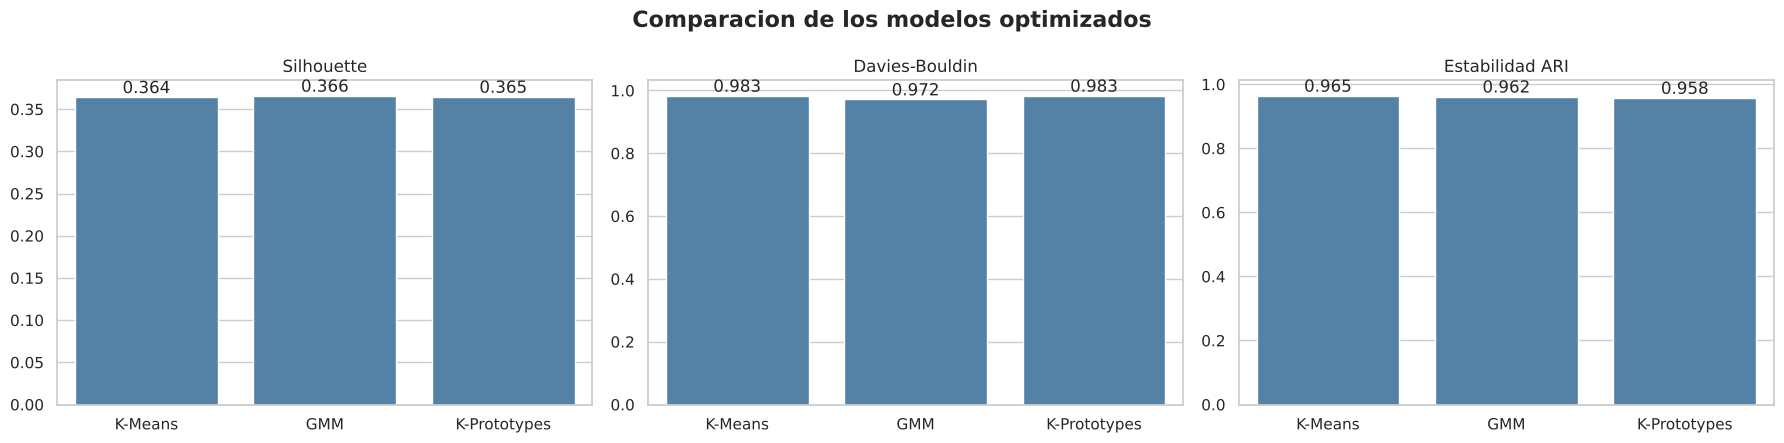

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
fig.suptitle("Comparacion de los modelos optimizados", fontsize=16, fontweight="bold")

for ax, (col, titulo) in zip(
    axes,
    [
        ("silhouette", "Silhouette"),
        ("davies_bouldin", "Davies-Bouldin"),
        ("estabilidad (ARI)", "Estabilidad ARI"),
    ],
):
    sns.barplot(data=df_comparacion, x="modelo", y=col, color="steelblue", ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.3f")
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

---

## **Entrenamiento del modelo final**

El modelo ganador se reentrena con la totalidad de los clientes. Los clusters se renumeran de menor a mayor monto mediano para que su identificador sea interpretable.


In [22]:
ganador = df_comparacion.sort_values("silhouette", ascending=False).iloc[0]["modelo"]
params_final = mejores[ganador]
print(f"Modelo ganador: {ganador} {params_final}")

idx_todos = np.arange(len(X_all))
idx_train = idx_busqueda[:N_KPROTO] if ganador == "K-Prototypes" else idx_todos
modelo_final, labels, _ = ajustar_y_predecir(ganador, params_final, idx_train, idx_todos)

df_debito["cluster"] = labels
orden = df_debito.groupby("cluster")["valor_total"].median().sort_values().index
df_debito["cluster"] = df_debito["cluster"].map({c: i for i, c in enumerate(orden)})
df_debito_procesado["cluster"] = df_debito["cluster"]

display(df_debito[["recency_dias", "frecuencia", "valor_total", "cluster"]].head())

Modelo ganador: GMM {'n_clusters': 3, 'covariance_type': 'spherical', 'reg_covar': 0.09923214949228372, 'init_params': 'kmeans'}


,recency_dias,frecuencia,valor_total,cluster
5080290,23,14,471512,1
2077692,8,55,3321655,2
5017407,77,14,688371,0
4877830,6,97,7667732,2
4752156,13,27,2084608,1


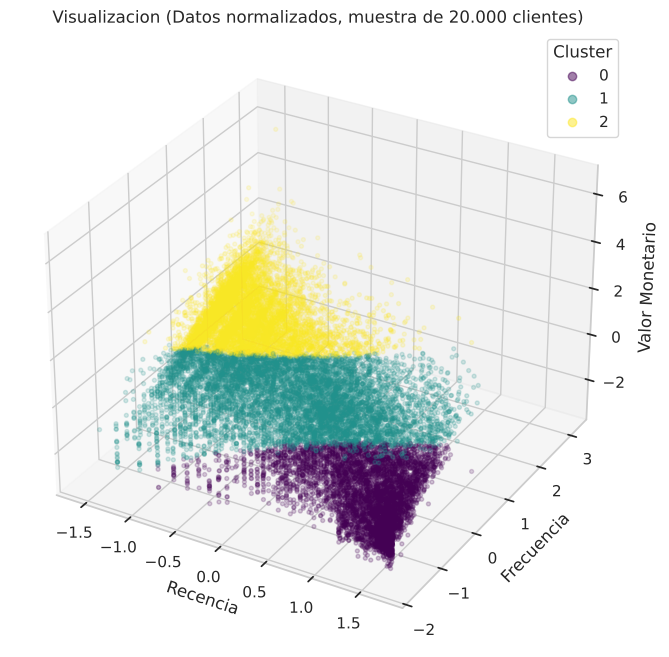

In [23]:
muestra = df_debito_procesado.sample(20_000, random_state=SEED)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    muestra["recency_dias"],
    muestra["frecuencia"],
    muestra["valor_total"],
    c=muestra["cluster"],
    cmap="viridis",
    s=8,
    alpha=0.5,
)

ax.set_title("Visualizacion (Datos normalizados, muestra de 20.000 clientes)")
ax.set_xlabel("Recencia")
ax.set_ylabel("Frecuencia")
ax.set_zlabel("Valor Monetario")
ax.legend(*scatter.legend_elements(), title="Cluster")

plt.show()

---

## **Perfilamiento de los segmentos**


In [24]:
perfil = df_debito.groupby("cluster").agg(
    clientes=("cluster", "size"),
    recencia_mediana=("recency_dias", "median"),
    frecuencia_mediana=("frecuencia", "median"),
    monto_mediano=("valor_total", "median"),
    monto_total=("valor_total", "sum"),
)
perfil.insert(1, "% clientes", perfil["clientes"] / perfil["clientes"].sum())
perfil["% del monto total"] = perfil.pop("monto_total") / df_debito["valor_total"].sum()

display(
    perfil.style.format(
        {
            "clientes": "{:,.0f}",
            "% clientes": "{:.1%}",
            "recencia_mediana": "{:.0f} dias",
            "frecuencia_mediana": "{:.0f}",
            "monto_mediano": "${:,.0f}",
            "% del monto total": "{:.1%}",
        }
    )
)

,clientes,% clientes,recencia_mediana,frecuencia_mediana,monto_mediano,% del monto total
cluster,,,,,,
0,"169,760",26.6%,75 dias,3,"$203,400",2.1%
1,"243,143",38.1%,15 dias,22,"$1,655,944",18.7%
2,"225,037",35.3%,7 dias,93,"$7,192,230",79.2%


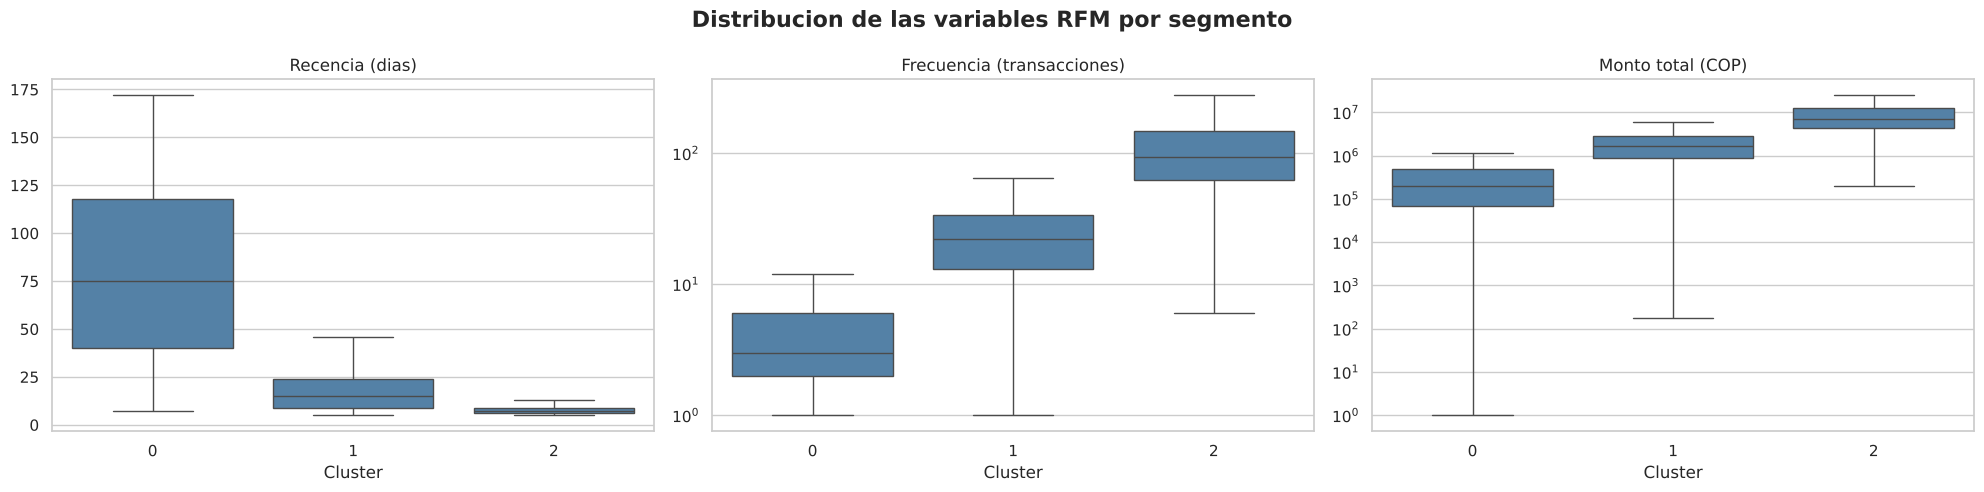

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle("Distribucion de las variables RFM por segmento", fontsize=16, fontweight="bold")

for ax, (col, titulo, log) in zip(
    axes,
    [
        ("recency_dias", "Recencia (dias)", False),
        ("frecuencia", "Frecuencia (transacciones)", True),
        ("valor_total", "Monto total (COP)", True),
    ],
):
    sns.boxplot(data=df_debito, x="cluster", y=col, color="steelblue", showfliers=False, ax=ax)
    if log:
        ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

Composicion de cada segmento segun las variables categoricas (segmento comercial y genero), en porcentaje de clientes del cluster.


In [26]:
for col in cat_cols:
    tabla = pd.crosstab(
        df_debito["cluster"].to_numpy(),
        df_debito[col].to_numpy(),
        normalize="index",
        rownames=["cluster"],
        colnames=[col],
    )
    display(tabla.style.format("{:.1%}").background_gradient(axis=None, cmap="Blues"))


desc_segmento,EMPRESARIAL,INDEPENDIENTES,PERSONAL,PLUS,PREFERENCIAL,PYME,SEGMENTO SOCIAL
cluster,,,,,,,
0,0.0%,15.9%,71.3%,11.6%,0.8%,0.4%,0.0%
1,0.0%,15.9%,66.4%,16.2%,0.9%,0.6%,0.0%
2,0.0%,14.6%,49.1%,33.0%,2.4%,0.9%,0.0%


desc_genero,FEMENINO,MASCULINO,NO BINARIO,TRANS
cluster,,,,
0,51.2%,48.8%,0.0%,0.0%
1,53.0%,47.0%,0.0%,0.0%
2,50.2%,49.8%,0.0%,0.0%


---

## **Conclusiones**

**Sobre la optimizacion**

- Los tres algoritmos convergen a la misma estructura: **3 segmentos** con silhouette entre 0.365 y 0.368. La restriccion de tamano minimo (5%) descarto entre 1 y 9 configuraciones por estudio.
- Con el mismo presupuesto, **TPE fue la unica estrategia que mejoro el resultado en GMM** (0.368 vs 0.359 de Grid y Random), porque puede explorar valores continuos de `reg_covar` que la malla no contiene y concentra las evaluaciones en las zonas prometedoras.
- En K-Means y K-Prototypes las tres estrategias llegan al mismo optimo, pero Random y TPE lo encuentran en la 2a evaluacion mientras que Grid necesita 17 en K-Means: con espacios pequenos y discretos el Grid Search es suficiente, pero desperdicia presupuesto.

**Sobre los modelos**

- En la muestra reservada el **GMM** obtiene el mejor silhouette (0.366) y el mejor Davies-Bouldin (0.972), aunque la diferencia frente a K-Means es minima. Los tres modelos son estables (ARI ≈ 0.96).
- K-Prototypes no aporta valor: el `gamma` optimo es pequeno (las variables categoricas casi no influyen) y es ~60 veces mas lento de entrenar. El segmento comercial y el genero no explican el comportamiento de compra.

**Sobre los segmentos**

| Cluster | Clientes | Perfil | Recencia | Frecuencia | Monto mediano | % del monto |
|---|---|---|---|---|---|---|
| 0 | 26.6% | Inactivos / en riesgo | 75 dias | 3 | $203 mil | 2.1% |
| 1 | 38.1% | Ocasionales | 15 dias | 22 | $1.7 M | 18.7% |
| 2 | 35.3% | Alto valor | 7 dias | 93 | $7.2 M | 79.2% |

El 35% de los clientes concentra casi el 80% del monto transado, y en ese grupo hay mas clientes PLUS y PREFERENCIAL. Los segmentos sugieren acciones distintas: reactivacion para el cluster 0, incentivos de uso para el 1 y fidelizacion para el 2.
